In [1]:
import gstools as gs
from matplotlib import pyplot as plt
import lmfit
import numpy as np

import strucfunc
import bfunc
import bplot

In [2]:
pix = pc = 1
len_scale = 10
m_exp = 1
m_gaussian = 2

In [3]:
def strucfunc_results_compiler(rslt, vv, pix, pc):
    rslt["Unweighted mean velocity"] = np.mean(vv)
    rslt["Unweighted sigma^2"] = np.var(vv)
    b2    = rslt['Unweighted B(r)']
    e_b2  = b2  *.1
    s     = 10**rslt['log10 r'] * pix * pc
    e_s   = s  *.1
    sig2  = rslt['Unweighted sigma^2']
    sig   = sig2**0.5

    return b2, e_b2, s, e_s

In [4]:
x = y = range(100)

## Gaussian

In [5]:
model_gaussian = gs.Gaussian(dim=2, var=1, len_scale=len_scale)
srf_gaussian   = gs.SRF(model_gaussian, seed=20170519)

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\gstools\field\plot.py:401: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'Field 2D structured: (100, 100)'}, xlabel='$x$', ylabel='$y$'>

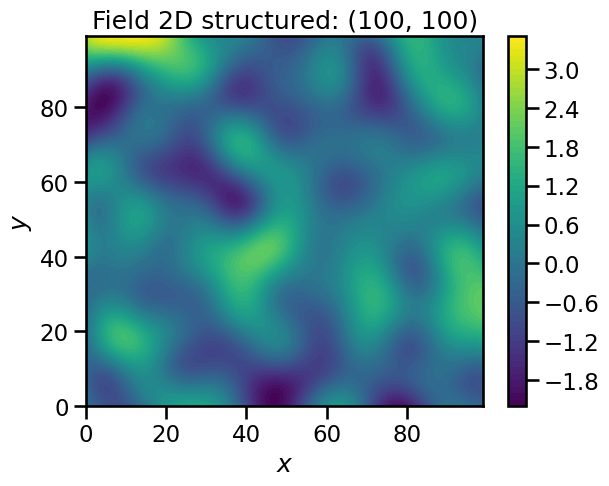

In [6]:
field_gaussian = srf_gaussian.structured([x, y])
srf_gaussian.plot()

In [7]:
rslt_gaussian = strucfunc.strucfunc_numba_parallel(field_gaussian, dlogr=0.05)

b2_gaussian, e_b2_gaussian, s_gaussian, e_s_gaussian = strucfunc_results_compiler(rslt_gaussian, field_gaussian, pix, pc)

rslt_gaussian["Unweighted mean velocity"] = np.mean(field_gaussian)
rslt_gaussian["Unweighted sigma^2"] = np.var(field_gaussian)
sig2_gaussian  = rslt_gaussian['Unweighted sigma^2']
sig_gaussian   = sig2_gaussian**0.5

C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\strucfunc.py:83: RuntimeWarning: invalid value encountered in divide
  'Unweighted B(r)': sf/nsf,
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\strucfunc.py:84: RuntimeWarning: invalid value encountered in divide
  'Weighted B(r)': wsf/weight}


## Exponential

In [8]:
model_exp = gs.Exponential(dim=2, var=1, len_scale=len_scale)
srf_exp   = gs.SRF(model_exp, seed=20170519)

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\gstools\field\plot.py:401: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'Field 2D structured: (100, 100)'}, xlabel='$x$', ylabel='$y$'>

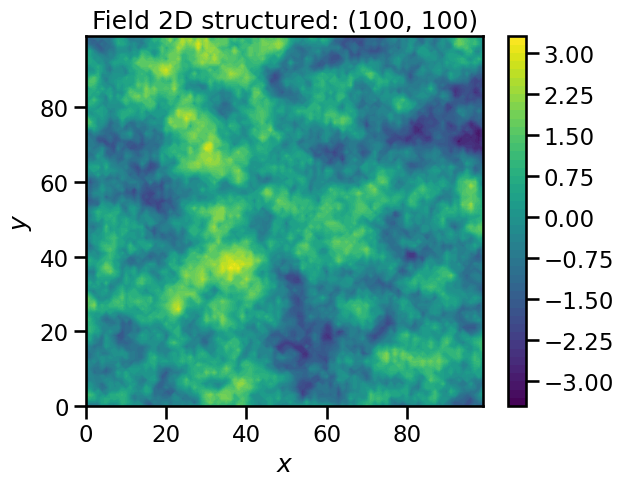

In [9]:
field_exp = srf_exp.structured([x, y])
srf_exp.plot()

In [10]:
rslt_exp = strucfunc.strucfunc_numba_parallel(field_exp, dlogr=0.05)

b2_exp, e_b2_exp, s_exp, e_s_exp = strucfunc_results_compiler(rslt_exp, field_exp, pix, pc)

rslt_exp["Unweighted mean velocity"] = np.mean(field_exp)
rslt_exp["Unweighted sigma^2"] = np.var(field_exp)
sig2_exp  = rslt_exp['Unweighted sigma^2']
sig_exp  = sig2_exp**0.5

In [13]:
len_scale*(np.log(2)**(1/m_exp))

6.931471805599453

## Model plot comparison

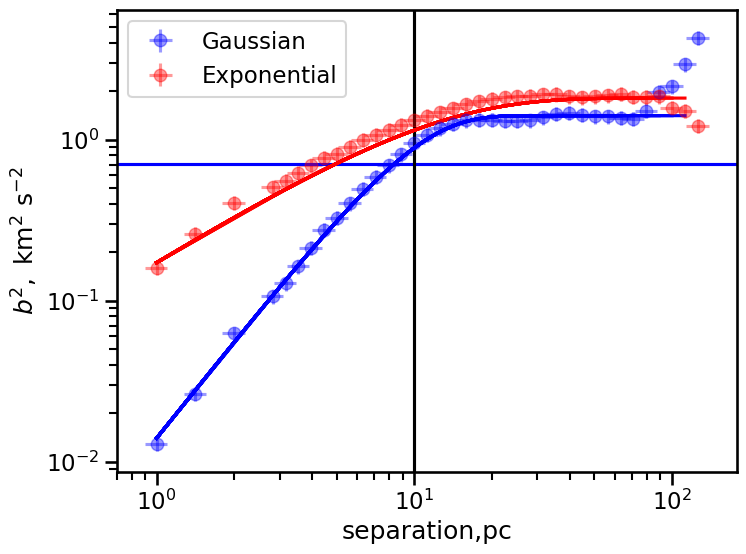

In [12]:
rgrid = np.linspace(s_gaussian[0], s_gaussian[:-1])

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(s_gaussian, b2_gaussian, yerr=e_b2_gaussian, xerr=e_s_gaussian, fmt='o', alpha=0.4,color="blue", label = 'Gaussian')
ax.errorbar(s_exp, b2_exp, yerr=e_b2_exp, xerr=e_s_exp, fmt='o', alpha=0.4,color="red", label = 'Exponential')

ax.axhline(sig2_gaussian, ls='-', color = 'blue')
ax.axvline(len_scale, ls='-', color='black')

ax.plot(rgrid, bfunc.bfunc00s(rgrid, len_scale*(np.log(2)**(1/m_gaussian)), sig2_gaussian, m_gaussian), color='blue')
ax.plot(rgrid, bfunc.bfunc00s(rgrid, len_scale*(np.log(2)**(1/m_exp)), sig2_exp, m_exp), color='red')
#ax.plot(rgrid, bfunc.bfunc00s(rgrid, 8, sig2_gaussian, m_gaussian), color='blue', linestyle=':')
#ax.plot(rgrid, bfunc.bfunc00s(rgrid, 6, sig2_exp, m_exp), color='red', linestyle=':')
#ax.plot(rgrid, bfunc.bfunc03s(rgrid, r0, sig2, m, s0, noise), color="black")
#ax.plot(rgrid, bfunc.bfunc04s(rgrid, r0, sig2, m, s0, noise, box_size), color="black")


ax.set(xscale='log', yscale='log', 
       xlabel='separation,pc',
       ylabel=r'$b^2,\ \mathrm{km^2\ s^{-2}}$'
      )
None

plt.legend()
plt.show()